# Residual adaptive global aggregation

Figure 5: prediction error, neighbor age coherence, and sampling stability.

In [1]:
import warnings
warnings.filterwarnings('ignore', message='IProgress not found.*')
from pathlib import Path
import json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon, pearsonr
from scdecage.tutorials_utils.plotting import DATA_ROOT, setup, output, letter, show_figure
DATA = Path('outputs/model_analyses/global_aggregation')
OUT = Path('outputs/figures')
OUT.mkdir(parents=True, exist_ok=True)
BLUE, PALE, GREY, SALMON = '#648DA3', '#C6DEE8', '#B8B8B2', '#CD886E'
setup()
PLOT_CONFIG = {'export_dpi': 800, 'display_width_fraction': 0.45, 'display_width_px': 480,
               'inline_max_pixels': [1100, 1600], 'bootstrap_draws': 2000,
               'cell_budget': 500, 'figure': 'Figure5', 'dataset': 'OneK1K'}

## Model-based aggregation experiment

Saved outputs show the manuscript panels. Supply the checkpoint, prepared data, and ordered test cells for each test partition to rerun the combined analysis.

In [ ]:
import torch
import math
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from scdecage.tutorials_utils.inference import load_experiment_model, infer_donor, precision_context

@torch.inference_mode()
def interpolate_prediction(aggregator, reps, ids, values, pathways, alpha):
    with precision_context(reps.device):
        cells = aggregator.cell_proj(reps)
        mean = cells.mean(0)
        weights = aggregator.cell_weight_head(cells).squeeze(-1).softmax(0)
        state = aggregator.base_norm(mean + torch.sigmoid(aggregator.global_adapt_gate)
                                     * alpha * (weights @ (cells - mean)))
        raw = aggregator.base_head(state).squeeze(-1)
        raw = raw + torch.sigmoid(aggregator.gene_gate) * (aggregator.gene_linear(ids).squeeze(-1) * values).sum() / len(ids)
        routes = aggregator.pathway_routes()
        queries = aggregator._program_queries(routes)
        programs, *_ = aggregator._pathway_guided_cell_to_program_routing(cells, pathways, routes, queries)
        summary, context = aggregator._model_program_interactions(state, programs)
        pooling = (context @ aggregator.program_pool_query / math.sqrt(aggregator.d_model)).softmax(0)
        program_state = summary + pooling @ context
        raw = raw + torch.sigmoid(aggregator.global_program_gate) * aggregator.concat_head(torch.cat([state, program_state])).squeeze(-1)
        return float(aggregator.age_center + aggregator.age_half * torch.tanh(raw))

@torch.inference_mode()
def aggregation_experiment(model_inputs, directory):
    directory.mkdir(parents=True, exist_ok=True)
    donors, interpolation, views = [], [], []
    rng = np.random.default_rng()
    for specification in model_inputs:
        model, data = load_experiment_model(specification)
        current, means, states = [], [], []
        for item in data:
            ids, values, pathways, reps, result = infer_donor(model, item)
            full = float(result['pred_age'])
            row = {'donor_id': item['donor_id'], 'age_years': float(item['age']), 'raga_prediction': full}
            with precision_context(reps.device):
                cells = model.aggregator.cell_proj(reps)
                means.append(model.aggregator.base_norm(cells.mean(0)).float().cpu().numpy())
            states.append(result['donor_state'].float().cpu().numpy())
            for alpha in np.linspace(0, 1, 6):
                prediction = interpolate_prediction(model.aggregator, reps, ids, values, pathways, alpha)
                interpolation.append({'donor_id': item['donor_id'], 'age': float(item['age']), 'alpha': alpha, 'prediction': prediction})
                if alpha == 0:
                    row['mean_prediction'] = prediction
            current.append(row)
            for repeat in range(20):
                keep = torch.as_tensor(rng.choice(len(ids), min(320, len(ids)), replace=False), device=reps.device)
                with precision_context(reps.device):
                    prediction = float(model.aggregator.forward_one(reps[keep], ids[keep], values[keep], pathways[keep])['pred_age'])
                views.append({'donor_id': item['donor_id'], 'age': float(item['age']), 'repeat': repeat,
                              'full_prediction': full, 'prediction': prediction, 'n_cells': len(keep)})
        current = pd.DataFrame(current)
        for name, representations in [('mean', means), ('raga', states)]:
            z = StandardScaler().fit_transform(np.asarray(representations))
            neighbors = NearestNeighbors(n_neighbors=9).fit(z).kneighbors(z, return_distance=False)[:, 1:]
            current[f'{name}_neighbor_age_gap'] = abs(current.age_years.to_numpy()[:, None] - current.age_years.to_numpy()[neighbors]).mean(1)
        donors.append(current)
    combined = pd.concat(donors, ignore_index=True)
    if not combined.donor_id.is_unique:
        raise ValueError('Each donor must appear in one test partition.')
    combined.to_csv(directory / 'donor_intermediates.csv', index=False, float_format='%.17g')
    pd.DataFrame(interpolation).to_csv(directory / 'aggregation_interpolation.csv', index=False, float_format='%.17g')
    pd.DataFrame(views).to_csv(directory / 'random_views.csv', index=False, float_format='%.17g')


In [ ]:
MODEL_INPUTS = [
    {'checkpoint': '', 'data_root': '', 'cell_order': ''},
]
aggregation_experiment(MODEL_INPUTS, DATA)


## Analysis calculations


In [2]:
def paired(ax, left, right, labels, ylabel, ptext=True, connect=True, annotation_fontsize=9):
    rng = np.random.default_rng(random.randrange(2 ** 32))
    if connect:
        for a, b in zip(left, right):
            ax.plot([0, 1], [a, b], color=PALE, alpha=0.12, lw=0.45, zorder=1)
    box = ax.boxplot([left, right], positions=[0, 1], widths=0.45, patch_artist=True, showfliers=False, medianprops={'color': '#45515B', 'lw': 1.0})
    for patch, color in zip(box['boxes'], [PALE, BLUE]):
        patch.set_facecolor(color)
        patch.set_alpha(0.8)
    for i, values in enumerate([left, right]):
        ax.scatter(i + rng.normal(0, 0.075, len(values)), values, s=3, alpha=0.2, color=BLUE, edgecolors='none', rasterized=True)
    ax.set_xticks([0, 1], labels)
    ax.set_ylabel(ylabel)
    ax.grid(axis='y')
    ax.set_axisbelow(True)
    if ptext:
        mask = np.isfinite(left) & np.isfinite(right)
        p = wilcoxon(np.asarray(left)[mask], np.asarray(right)[mask]).pvalue if mask.sum() > 4 and (not np.allclose(np.asarray(left)[mask], np.asarray(right)[mask])) else 1.0
        ax.text(0.98, 0.98, f'Paired Wilcoxon P={p:.2g}', ha='right', va='top', transform=ax.transAxes, fontsize=annotation_fontsize, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 2})

def mean_ci(values, random_state=random.randrange(2 ** 32)):
    values = np.asarray(values, float)
    values = values[np.isfinite(values)]
    rng = np.random.default_rng(random_state)
    boot = rng.choice(values, (PLOT_CONFIG['bootstrap_draws'], len(values)), replace=True).mean(1)
    return (values.mean(), *np.quantile(boot, [0.025, 0.975]))
def figure5(root):
    d = pd.read_csv(root / 'donor_intermediates.csv', float_precision='round_trip')
    p = pd.read_csv(root / 'aggregation_interpolation.csv', float_precision='round_trip')
    v = pd.read_csv(root / 'random_views.csv', float_precision='round_trip')
    directory = OUT / 'figure5'
    settings = {'A_ymax': 45, 'B_ymax': 30, 'B_neighbors': 8, 'D_ylim': [-6, 6]}
    displayed_neighbors = int(settings.get('B_neighbors', 8))
    assert displayed_neighbors == 8

    def panel_a(ax):
        left = abs(d.mean_prediction - d.age_years).to_numpy()
        right = abs(d.raga_prediction - d.age_years).to_numpy()
        paired(ax, left, right, ['Global mean\naggregation', 'Residual adaptive global\naggregation'], 'Absolute error', connect=False, annotation_fontsize=11.5)
        ax.set_ylim(0, 45)
        ax.text(0.02, 0.98, f'MAE: {left.mean():.2f} → {right.mean():.2f}', transform=ax.transAxes, va='top', fontsize=11.5)
        letter(ax, 'A')

    def panel_b(ax):
        left, right = [d[f'{method}_neighbor_age_gap'].to_numpy() for method in ['mean', 'raga']]
        paired(ax, left, right, ['Global mean\naggregation', 'Residual adaptive global\naggregation'], 'Mean age gap to 8 nearest test donors', connect=False, annotation_fontsize=11.5)
        for patch, color in zip(ax.patches, [GREY, BLUE]):
            patch.set_facecolor(color)
        ax.text(0.02, 0.98, f'Mean: {left.mean():.2f} → {right.mean():.2f}', transform=ax.transAxes, va='top', fontsize=11.5)
        if settings.get('B_ymax') is not None:
            ax.set_ylim(0, 30)
        letter(ax, 'B')

    def panel_c(ax):
        rows = []
        for level, g in p.groupby('alpha'):
            mu, lo, hi = mean_ci(abs(g.prediction - g.age))
            rows.append((level, mu, lo, hi))
        x, mu, lo, hi = np.asarray(rows).T
        ax.plot(x, mu, 'o-', color=BLUE, ms=4)
        ax.fill_between(x, lo, hi, color=PALE, alpha=0.55)
        for i, (level, value) in enumerate(zip(x, mu)):
            ax.annotate(f'{value:.2f}', (level, value), xytext=(7, 5 if i == 0 else 7), textcoords='offset points', fontsize=11.5, ha='left', va='bottom', color='#374C59')
        ax.margins(x=0.09)
        ax.set_xlabel('Contribution of learned cellular weights')
        ax.set_ylabel('MAE')
        ax.grid()
        letter(ax, 'C')

    def panel_d(ax):
        summary = v.groupby('donor_id').agg(full=('full_prediction', 'first'), prediction=('prediction', 'mean'), lo=('prediction', lambda x: x.quantile(0.025)), hi=('prediction', lambda x: x.quantile(0.975)))
        drift = summary.prediction - summary.full
        ax.vlines(summary.full, summary.lo - summary.full, summary.hi - summary.full, color=PALE, alpha=0.12, lw=0.35, zorder=1)
        ax.scatter(summary.full, drift, s=7, c=BLUE, alpha=0.45, edgecolors='none', rasterized=True)
        ax.axhline(0, c='#7A858B', lw=0.8)
        ax.text(0.03, 0.97, f'r = {pearsonr(summary.full, summary.prediction).statistic:.3f}\nMean absolute drift = {abs(drift).mean():.3f}', transform=ax.transAxes, va='top', fontsize=11.5)
        ax.set_xlabel('Full 500-cell prediction')
        ax.set_ylabel('Sampling-induced deviation')
        ax.grid()
        letter(ax, 'D')
        ax.set_ylim(settings['D_ylim'])

    def enlarge(ax):
        ax.xaxis.label.set_fontsize(13)
        ax.yaxis.label.set_fontsize(13)
        ax.tick_params(axis='both', labelsize=11.5)
        ax.title.set_fontsize(14)
    functions = [panel_a, panel_b, panel_c, panel_d]
    directory = OUT / 'figure5'
    for label, fn in zip('ABCD', functions):
        fig, ax = plt.subplots(figsize=(6.4, 4.6))
        fn(ax)
        enlarge(ax)
        output(fig, directory, 'Figure5' + label)


## Prediction error

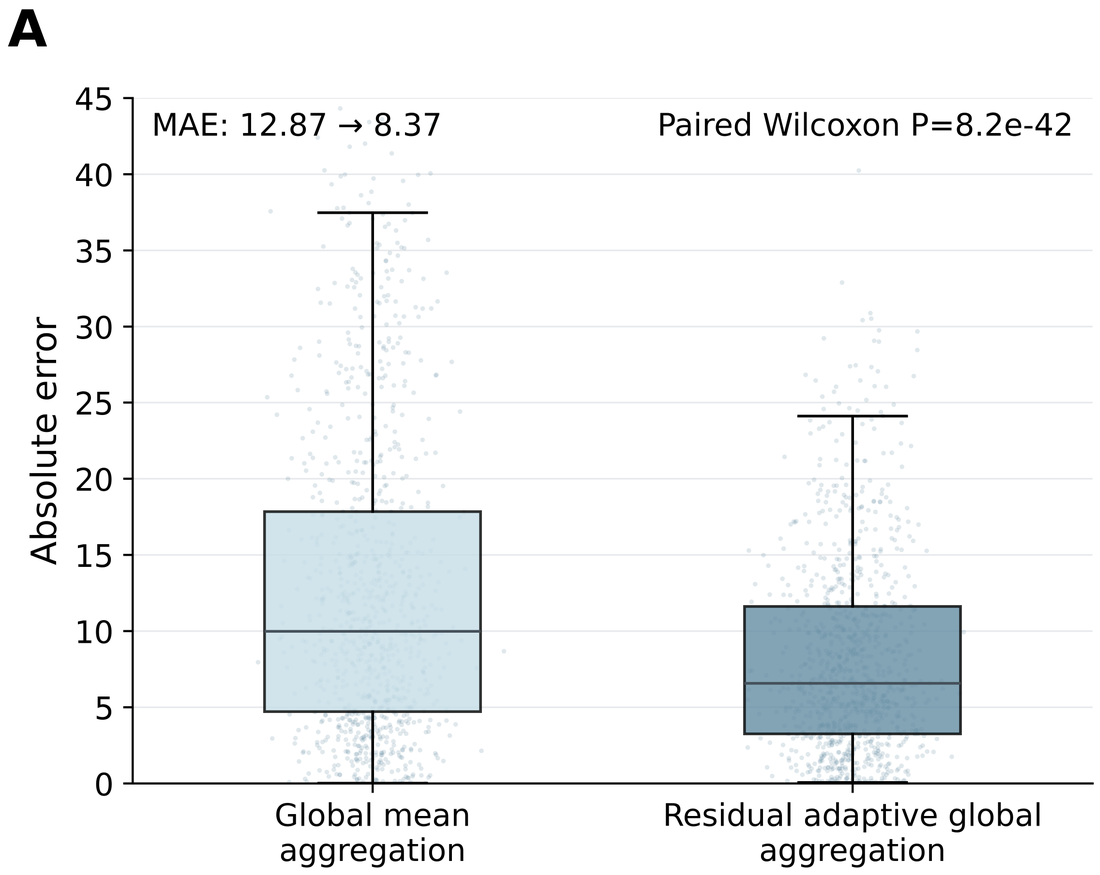

In [3]:
figure5(DATA)
show_figure(OUT / 'figure5/Figure5A.png')


## Neighbor age coherence

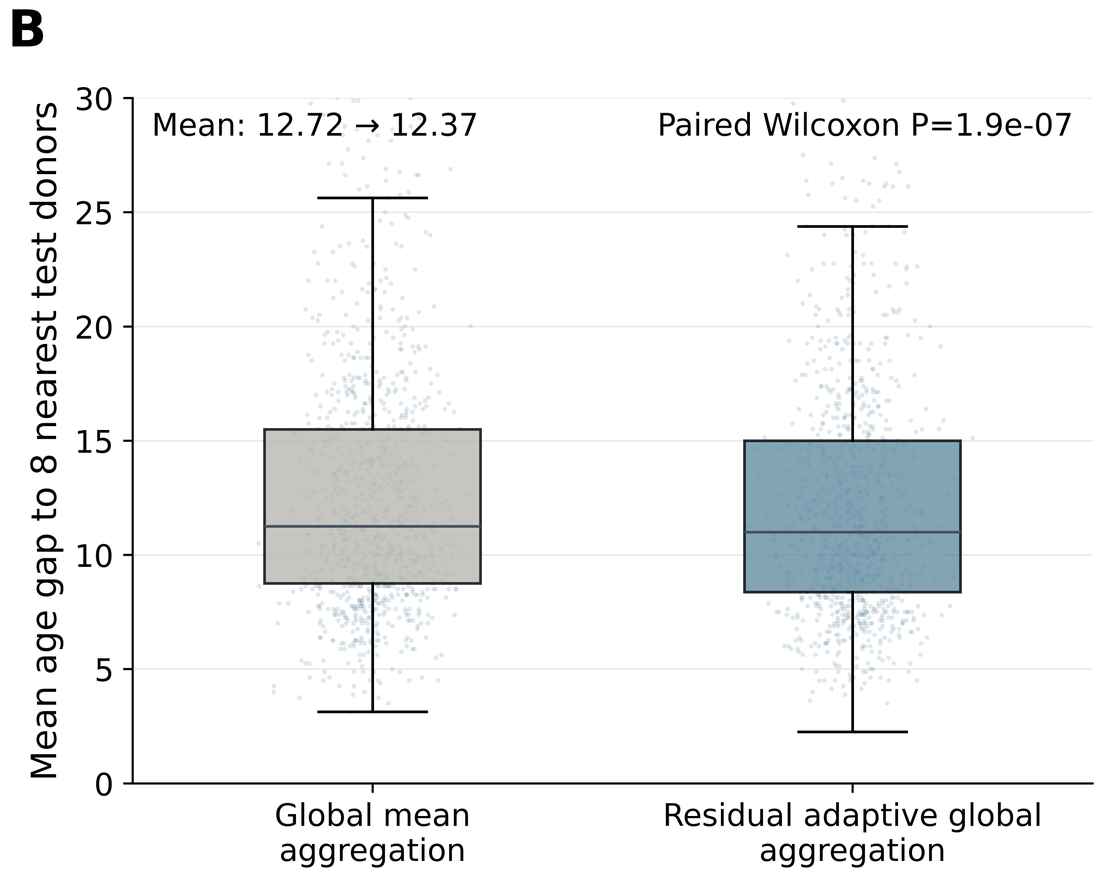

In [4]:
show_figure(OUT / 'figure5/Figure5B.png')


## Aggregation-weight interpolation

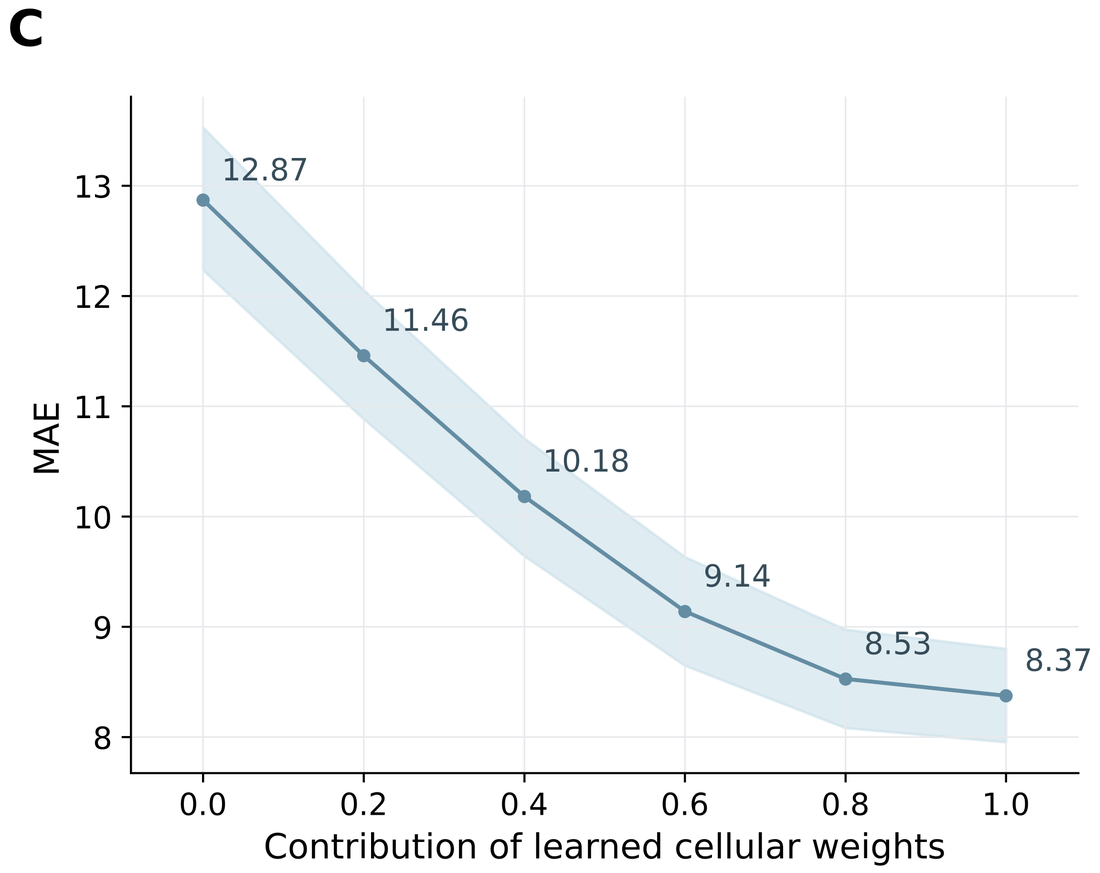

In [5]:
show_figure(OUT / 'figure5/Figure5C.png')


## Sampling stability

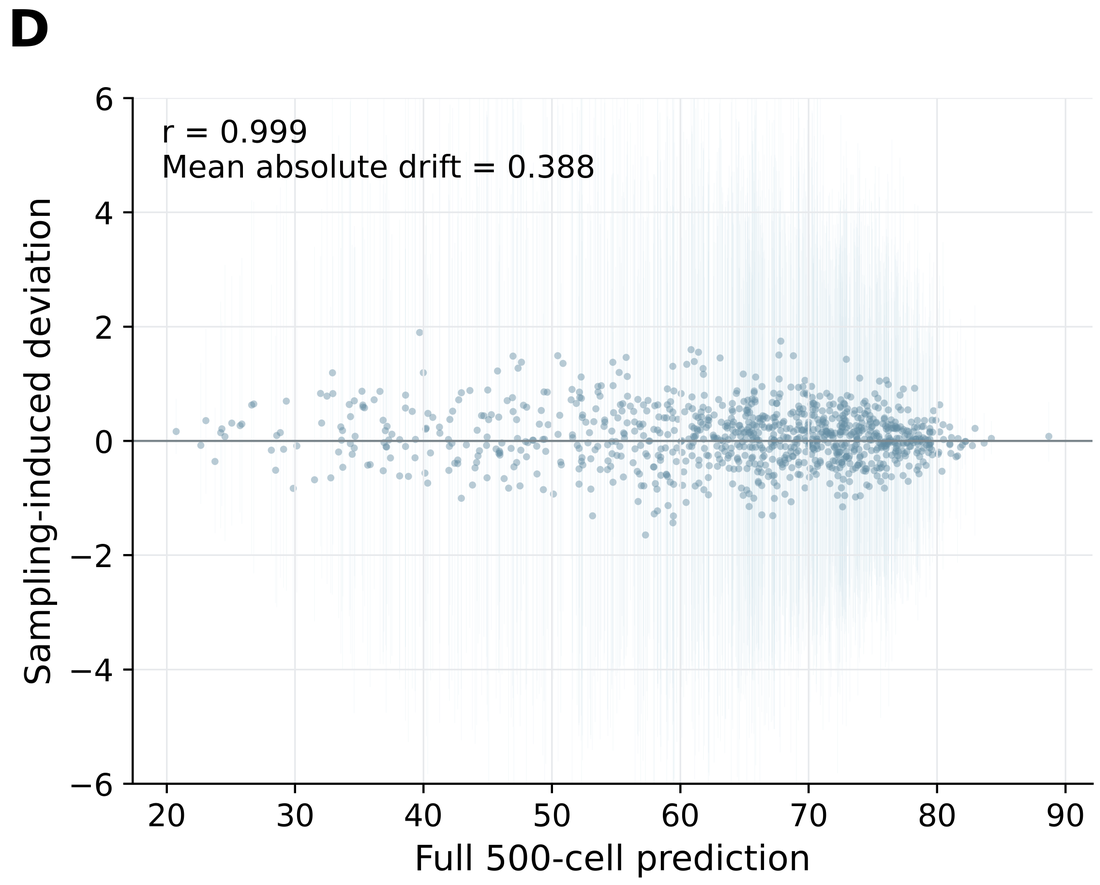

In [6]:
show_figure(OUT / 'figure5/Figure5D.png')
